# Modelagem preditiva da produtividade da safra de soja com uso de aprendizado de máquina e dados agrometeorológicos — Modelagem (Etapa 1: modelo base)

**Integrantes:**
**Orientador:**

**Síntese do conteúdo deste arquivo:** a partir do painel município–safra gerado em `analise_exploratoria.ipynb` (`dataset/processed/painel_municipio_safra.csv`), treina e compara quatro abordagens para prever o rendimento da soja (kg/ha): (0) baseline ingênua sem clima (tendência estadual + efeito histórico do município), (1) regressão linear múltipla (OLS), (2) Random Forest e (3) Gradient Boosting. Usa apenas o clima das estações INMET (estação mais próxima) e o ONI, com validação temporal (treino nas safras 2000–2020, teste nas safras 2021–2025). Avalia RMSE, MAE e R², o erro por safra, a importância das variáveis e a relação do erro com a distância até a estação — insumo para decidir se vale complementar o clima com uma fonte em grade (NASA POWER) na Etapa 3.

| Data       | Autor           | Descrição                                                                 |
|------------|-----------------|-----------------------------------------------------------------------------|
| 2026-10-22 |                 | Criação do notebook — modelo base (baseline, OLS, Random Forest, Gradient Boosting) com validação temporal |

## 1. Imports e configuração

Assim como o notebook exploratório, este notebook assume que é executado a partir da
pasta `notebooks/`, lendo o painel em `../dataset/processed/` e as coordenadas em
`../dataset/raw/`.

O *Gradient Boosting* usa o `HistGradientBoostingRegressor` do scikit-learn — mesma
família de algoritmo do XGBoost/LightGBM (árvores de decisão em sequência, cada uma
corrigindo o erro das anteriores), sem exigir biblioteca extra.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor, HistGradientBoostingRegressor
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score
from sklearn.inspection import permutation_importance

RAW = "../dataset/raw"
PROCESSED = "../dataset/processed"

ANO_CORTE = 2020   # treino: safras <= 2020 | teste: safras 2021-2025
SEED = 42

pd.set_option("display.max_columns", 20)
pd.set_option("display.float_format", lambda v: f"{v:,.2f}")
print("Ambiente pronto.")

Ambiente pronto.


## 2. Carga do painel e seleção das linhas completas

A variável-alvo é o **rendimento** (`rendimento_kg_ha`). A produção de um município
pode ser obtida depois, multiplicando o rendimento previsto pela área plantada.

Só entram no modelo as linhas com rendimento **e** clima do INMET (chuva e temperatura
na janela da safra). O ONI está disponível para todas as safras. As coordenadas
(latitude/longitude) de cada município vêm da mesma base auxiliar usada no notebook
exploratório.

In [2]:
painel = pd.read_csv(f"{PROCESSED}/painel_municipio_safra.csv")
coords = (pd.read_csv(f"{RAW}/municipios_brasil_coords.csv",
                      usecols=["codigo_ibge", "latitude", "longitude"])
          .rename(columns={"codigo_ibge": "codigo_ibge_municipio"}))
painel = painel.merge(coords, on="codigo_ibge_municipio", how="left")

ALVO = "rendimento_kg_ha"
CHUVA = "precipitacao_total_safra_mm"
TEMP = "temperatura_media_safra_c"
ONI = "oni_media_safra"

com_rendimento = painel.dropna(subset=[ALVO])
df = com_rendimento.dropna(subset=[CHUVA, TEMP]).copy()

print(f"Linhas do painel:                    {len(painel):>6}")
print(f"  com rendimento:                    {len(com_rendimento):>6}")
print(f"  com rendimento + clima (modelagem): {len(df):>6}")
print(f"Municípios na base de modelagem:     {df['codigo_ibge_municipio'].nunique():>6}")
print("Sem coordenadas:", df["latitude"].isna().sum())

Linhas do painel:                     12922
  com rendimento:                     10540
  com rendimento + clima (modelagem):   5869
Municípios na base de modelagem:        448
Sem coordenadas: 0


## 3. Divisão temporal treino/teste

A divisão **não é aleatória**. Todos os municípios de uma mesma safra compartilham o
mesmo ano climático (mesmo ONI, secas que atingem o estado inteiro). Se as linhas
fossem sorteadas, o modelo veria parte de cada safra no treino e "aprenderia" o ano —
o erro de teste ficaria artificialmente baixo. Com a divisão temporal, o teste simula
a situação real: prever safras que o modelo nunca viu.

- **Treino:** safras 2000–2020
- **Teste:** safras 2021–2025 (inclui as secas de 2022, 2023 e 2025, um teste exigente)

In [3]:
treino = df[df["ano_safra"] <= ANO_CORTE].copy()
teste = df[df["ano_safra"] > ANO_CORTE].copy()

print(f"Treino: {len(treino)} linhas ({treino['ano_safra'].min()}-{treino['ano_safra'].max()})")
print(f"Teste:  {len(teste)} linhas ({teste['ano_safra'].min()}-{teste['ano_safra'].max()})")
print()
print("Linhas por safra no teste:")
print(teste["ano_safra"].value_counts().sort_index().to_string())

Treino: 4125 linhas (2001-2020)
Teste:  1744 linhas (2021-2025)

Linhas por safra no teste:
2021    327
2022    289
2023    375
2024    400
2025    353


## 4. Variáveis derivadas (calculadas só com dados de treino)

1. **Tendência estadual:** reta `rendimento ~ ano` ajustada em todas as safras ≤ 2020
   com rendimento informado (mesmo as sem clima). Representa o ganho tecnológico
   (cultivares, manejo) ao longo do tempo.
2. **Efeito do município** (`efeito_municipio`): quanto, em média, o município fica
   acima ou abaixo da tendência estadual nas safras ≤ 2020. Representa o potencial
   local (solo, relevo, perfil dos produtores). No treino ele é calculado *deixando a
   própria linha de fora* (leave-one-out), para que o modelo não use o próprio
   rendimento como pista. Municípios sem histórico recebem 0 (média do estado).
3. **Chuva centrada, em centenas de mm** (`chuva_c100`) e seu quadrado
   (`chuva_c100_2`): a chuva é medida em relação à média do treino. Assim, o
   coeficiente linear da OLS vale "efeito de +100 mm a partir da média", e o
   quadrático capta que tanto pouca quanto muita chuva prejudicam a lavoura.

Nenhuma dessas contas usa as safras de teste, para não haver vazamento de informação.

In [4]:
# 1. Tendência estadual (todas as linhas com rendimento até o corte)
historico = com_rendimento[com_rendimento["ano_safra"] <= ANO_CORTE].copy()
tendencia = LinearRegression().fit(historico[["ano_safra"]], historico[ALVO])
print(f"Tendência estadual: {tendencia.coef_[0]:+.1f} kg/ha por ano")

# 2. Efeito do município (resíduo médio em relação à tendência)
historico["residuo"] = historico[ALVO] - tendencia.predict(historico[["ano_safra"]])
efeito = historico.groupby("codigo_ibge_municipio")["residuo"].agg(["sum", "count"])

# 3. Chuva centrada na média do treino
CHUVA_MEDIA = treino[CHUVA].mean()


def preparar(d, eh_treino):
    d = d.copy()
    d["tendencia_kg_ha"] = tendencia.predict(d[["ano_safra"]])
    e = d[["codigo_ibge_municipio"]].join(efeito, on="codigo_ibge_municipio")
    soma, n = e["sum"].fillna(0), e["count"].fillna(0)
    if eh_treino:
        # leave-one-out: tira a própria linha da média do município
        residuo_proprio = d[ALVO] - d["tendencia_kg_ha"]
        soma, n = soma - residuo_proprio, n - 1
    d["efeito_municipio"] = np.where(n > 0, soma / n.where(n > 0, 1), 0.0)
    d["chuva_c100"] = (d[CHUVA] - CHUVA_MEDIA) / 100
    d["chuva_c100_2"] = d["chuva_c100"] ** 2
    return d


treino = preparar(treino, eh_treino=True)
teste = preparar(teste, eh_treino=False)
print(f"Chuva média no treino: {CHUVA_MEDIA:.0f} mm")
print("Municípios do teste sem histórico no treino:",
      teste.loc[~teste["codigo_ibge_municipio"].isin(efeito.index), "codigo_ibge_municipio"].nunique())
treino[["municipio", "ano_safra", ALVO, "tendencia_kg_ha", "efeito_municipio",
        "chuva_c100", TEMP, ONI]].head()

Tendência estadual: +74.0 kg/ha por ano
Chuva média no treino: 912 mm
Municípios do teste sem histórico no treino: 9


,municipio,ano_safra,rendimento_kg_ha,tendencia_kg_ha,efeito_municipio,chuva_c100,temperatura_media_safra_c,oni_media_safra
8,Aceguá - RS,2008,"1,740.00","2,144.73",-639.57,-3.74,21.11,-0.40
9,Aceguá - RS,2009,"1,750.00","2,218.69",-636.20,-3.57,20.94,-1.25
10,Aceguá - RS,2010,"1,750.00","2,292.65",-632.31,1.90,21.34,0.33
11,Aceguá - RS,2011,"2,400.00","2,366.61",-662.63,-5.52,21.16,0.11
12,Aceguá - RS,2012,"1,460.00","2,440.56",-609.26,-4.10,21.11,-1.08


### Conjuntos de variáveis de cada modelo

| Modelo | Variáveis |
|---|---|
| 0 — Baseline ingênua | tendência + efeito do município (sem clima, sem ajuste) |
| 1a — OLS só clima | ano, chuva, chuva², temperatura, ONI |
| 1b — OLS + município | as de 1a + efeito do município |
| 2 — Random Forest | ano, chuva, temperatura, ONI, latitude, longitude, efeito do município |
| 3 — Gradient Boosting | as mesmas do Random Forest |

A OLS 1b existe para uma comparação justa: a baseline já sabe o "potencial" de cada
município, então a pergunta certa é se o clima acrescenta algo *além* disso.
As árvores não precisam do termo quadrático (elas captam curvas sozinhas) e recebem
latitude/longitude para captar diferenças regionais.

In [5]:
FEAT_OLS_CLIMA = ["ano_safra", "chuva_c100", "chuva_c100_2", TEMP, ONI]
FEAT_OLS_MUN = FEAT_OLS_CLIMA + ["efeito_municipio"]
FEAT_ARVORE = ["ano_safra", CHUVA, TEMP, ONI, "latitude", "longitude", "efeito_municipio"]

y_treino, y_teste = treino[ALVO], teste[ALVO]
resultados = []
previsoes = {}


def avaliar(nome, pred):
    previsoes[nome] = pred
    resultados.append({
        "modelo": nome,
        "RMSE (kg/ha)": mean_squared_error(y_teste, pred) ** 0.5,
        "MAE (kg/ha)": mean_absolute_error(y_teste, pred),
        "R²": r2_score(y_teste, pred),
    })
    r = resultados[-1]
    print(f"{nome}: RMSE = {r['RMSE (kg/ha)']:.0f} | MAE = {r['MAE (kg/ha)']:.0f} | R² = {r['R²']:.3f}")

## 5. Modelo 0 — Baseline ingênua (sem clima)

Previsão = tendência estadual do ano + efeito histórico do município. Não usa nenhuma
informação climática nem ajusta parâmetros. É a régua mínima: um modelo com clima que
não supere esta previsão não está aproveitando o clima.

In [6]:
avaliar("0 - Baseline (tendência + município)",
        teste["tendencia_kg_ha"] + teste["efeito_municipio"])

0 - Baseline (tendência + município): RMSE = 1167 | MAE = 928 | R² = -0.740


## 6. Modelo 1 — Regressão Linear Múltipla (OLS)

Fórmula da versão 1a:

`rendimento ~ ano + chuva + chuva² + temperatura + ONI`

A versão 1b acrescenta o efeito do município. A tabela de coeficientes traz erro-padrão
e p-valor. **Atenção:** os p-valores assumem erros independentes, mas linhas da mesma
safra são correlacionadas (mesmo ano climático), então eles tendem a ser otimistas —
usar como indicação de sinal e magnitude, não como teste formal.

In [7]:
def tabela_ols(modelo, X, y):
    # Erro-padrão e p-valor clássicos da OLS a partir de (X'X)^-1
    Xc = np.column_stack([np.ones(len(X)), X.to_numpy(dtype=float)])
    beta = np.r_[modelo.intercept_, modelo.coef_]
    residuos = y.to_numpy() - Xc @ beta
    gl = len(y) - Xc.shape[1]
    sigma2 = residuos @ residuos / gl
    ep = np.sqrt(np.diag(sigma2 * np.linalg.inv(Xc.T @ Xc)))
    t = beta / ep
    return pd.DataFrame({"coeficiente": beta, "erro_padrao": ep, "t": t,
                         "p_valor": 2 * stats.t.sf(np.abs(t), gl)},
                        index=["intercepto"] + list(X.columns))


ols_clima = LinearRegression().fit(treino[FEAT_OLS_CLIMA], y_treino)
avaliar("1a - OLS (só clima)", ols_clima.predict(teste[FEAT_OLS_CLIMA]))

ols_mun = LinearRegression().fit(treino[FEAT_OLS_MUN], y_treino)
avaliar("1b - OLS (clima + município)", ols_mun.predict(teste[FEAT_OLS_MUN]))

print(f"\nR² no treino: 1a = {ols_clima.score(treino[FEAT_OLS_CLIMA], y_treino):.3f} | "
      f"1b = {ols_mun.score(treino[FEAT_OLS_MUN], y_treino):.3f}")
print("\nCoeficientes da OLS 1b (clima + município):")
tabela_ols(ols_mun, treino[FEAT_OLS_MUN], y_treino)

1a - OLS (só clima): RMSE = 901 | MAE = 731 | R² = -0.038
1b - OLS (clima + município): RMSE = 908 | MAE = 740 | R² = -0.055

R² no treino: 1a = 0.308 | 1b = 0.401

Coeficientes da OLS 1b (clima + município):


,coeficiente,erro_padrao,t,p_valor
intercepto,"-107,507.36","5,171.22",-20.79,0.00
ano_safra,55.50,2.57,21.64,0.00
chuva_c100,103.49,3.97,26.06,0.00
chuva_c100_2,-7.14,0.92,-7.75,0.00
temperatura_media_safra_c,-73.34,7.48,-9.81,0.00
oni_media_safra,10.64,14.50,0.73,0.46
efeito_municipio,0.71,0.03,25.39,0.00


**Como ler os coeficientes:** `chuva_c100` é o efeito, em kg/ha, de +100 mm de chuva
na safra a partir da média do treino; `chuva_c100_2` negativo indica que o ganho com
chuva diminui (e pode virar perda) quando ela fica muito acima da média;
`temperatura_media_safra_c` é o efeito de +1 °C na temperatura média da safra;
`oni_media_safra` é o efeito de +1 no índice ONI (mais El Niño); `efeito_municipio`
perto de 1 indica que o potencial histórico do município se mantém.

## 7. Modelo 2 — Random Forest

Conjunto de 500 árvores de decisão treinadas em amostras diferentes; a previsão é a
média delas. Capta relações não lineares e interações (ex.: calor combinado com seca)
sem precisar especificá-las. `min_samples_leaf=5` evita folhas com pouquíssimas linhas
(reduz sobreajuste). Hiperparâmetros fixos, sem ajuste fino nesta etapa.

In [8]:
rf = RandomForestRegressor(n_estimators=500, min_samples_leaf=5,
                           n_jobs=-1, random_state=SEED)
rf.fit(treino[FEAT_ARVORE], y_treino)
avaliar("2 - Random Forest", rf.predict(teste[FEAT_ARVORE]))
print(f"R² no treino: {rf.score(treino[FEAT_ARVORE], y_treino):.3f}")

2 - Random Forest: RMSE = 1033 | MAE = 856 | R² = -0.363
R² no treino: 0.897


## 8. Modelo 3 — Gradient Boosting

Árvores rasas treinadas em sequência, cada uma corrigindo o erro acumulado das
anteriores. Taxa de aprendizado baixa (0,05) com até 500 iterações e parada antecipada
(`early_stopping`, que separa 10% do treino para decidir quando parar).

In [9]:
gb = HistGradientBoostingRegressor(learning_rate=0.05, max_iter=500,
                                   min_samples_leaf=20, early_stopping=True,
                                   validation_fraction=0.1, random_state=SEED)
gb.fit(treino[FEAT_ARVORE], y_treino)
avaliar("3 - Gradient Boosting", gb.predict(teste[FEAT_ARVORE]))
print(f"Iterações usadas: {gb.n_iter_} | R² no treino: {gb.score(treino[FEAT_ARVORE], y_treino):.3f}")

3 - Gradient Boosting: RMSE = 993 | MAE = 827 | R² = -0.260
Iterações usadas: 297 | R² no treino: 0.899


## 9. Comparação dos modelos (safras de teste 2021–2025)

Todos os modelos foram avaliados exatamente nas mesmas linhas de teste.

In [10]:
comparacao = pd.DataFrame(resultados).set_index("modelo")
comparacao["RMSE vs baseline"] = (comparacao["RMSE (kg/ha)"]
                                  / comparacao.loc[comparacao.index[0], "RMSE (kg/ha)"] - 1)
print(f"Rendimento médio observado no teste: {y_teste.mean():.0f} kg/ha "
      f"(desvio-padrão {y_teste.std():.0f} kg/ha)")
comparacao.style.format({"RMSE (kg/ha)": "{:.0f}", "MAE (kg/ha)": "{:.0f}",
                         "R²": "{:.3f}", "RMSE vs baseline": "{:+.1%}"})

Rendimento médio observado no teste: 2477 kg/ha (desvio-padrão 885 kg/ha)


,RMSE (kg/ha),MAE (kg/ha),R²,RMSE vs baseline
modelo,,,,
0 - Baseline (tendência + município),1167,928,-0.740,+0.0%
1a - OLS (só clima),901,731,-0.038,-22.8%
1b - OLS (clima + município),908,740,-0.055,-22.1%
2 - Random Forest,1033,856,-0.363,-11.5%
3 - Gradient Boosting,993,827,-0.260,-14.9%


## 10. Erro por safra de teste

O desempenho médio esconde diferenças grandes entre safras. Aqui, para cada safra de
teste, comparamos o rendimento médio observado com o previsto por cada modelo e o RMSE
de cada um.

In [11]:
por_safra = teste[["ano_safra", ALVO]].copy()
for nome, pred in previsoes.items():
    por_safra[nome] = pred

media_safra = por_safra.groupby("ano_safra").mean()
rmse_safra = pd.DataFrame({
    nome: por_safra.groupby("ano_safra").apply(
        lambda g, n=nome: mean_squared_error(g[ALVO], g[n]) ** 0.5)
    for nome in previsoes
})
print("Rendimento médio por safra (kg/ha) — observado e previsto:")
display(media_safra.round(0))
print("RMSE por safra (kg/ha):")
display(rmse_safra.round(0))

Rendimento médio por safra (kg/ha) — observado e previsto:


,rendimento_kg_ha,0 - Baseline (tendência + município),1a - OLS (só clima),1b - OLS (clima + município),2 - Random Forest,3 - Gradient Boosting
ano_safra,,,,,,
2021,"3,293.00","3,093.00","2,812.00","2,796.00","2,046.00","2,064.00"
2022,"1,716.00","3,205.00","2,719.00","2,772.00","1,921.00","1,954.00"
2023,"2,075.00","3,218.00","2,629.00","2,651.00","1,942.00","1,991.00"
2024,"2,865.00","3,325.00","3,352.00","3,414.00","1,974.00","2,077.00"
2025,"2,330.00","3,395.00","2,892.00","2,925.00","1,966.00","1,943.00"


RMSE por safra (kg/ha):


,0 - Baseline (tendência + município),1a - OLS (só clima),1b - OLS (clima + município),2 - Random Forest,3 - Gradient Boosting
ano_safra,,,,,
2021,429.00,674.00,643.00,"1,390.00","1,352.00"
2022,"1,680.00","1,229.00","1,307.00",925.00,894.00
2023,"1,355.00",856.00,863.00,803.00,801.00
2024,794.00,867.00,810.00,"1,111.00",992.00
2025,"1,256.00",850.00,872.00,834.00,852.00


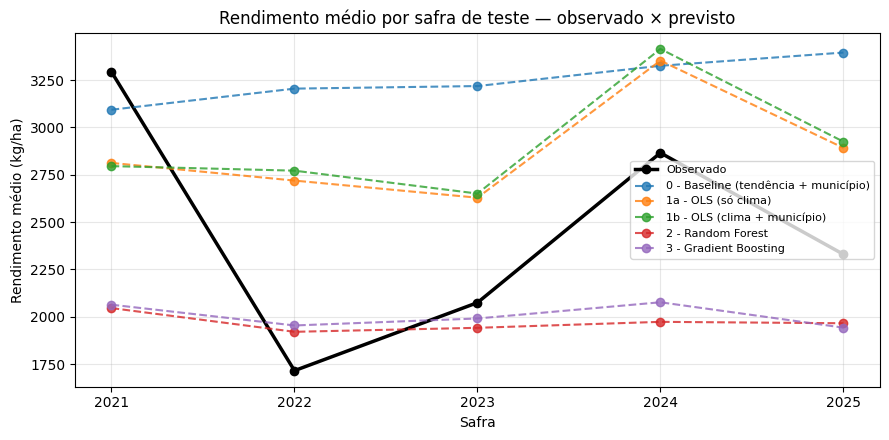

In [12]:
fig, ax = plt.subplots(figsize=(9, 4.5))
ax.plot(media_safra.index, media_safra[ALVO], "k-o", lw=2.5, label="Observado")
for nome in previsoes:
    ax.plot(media_safra.index, media_safra[nome], "--o", alpha=0.8, label=nome)
ax.set_xticks(media_safra.index)
ax.set_xlabel("Safra")
ax.set_ylabel("Rendimento médio (kg/ha)")
ax.set_title("Rendimento médio por safra de teste — observado × previsto")
ax.grid(alpha=0.3)
ax.legend(fontsize=8, loc="best")
plt.tight_layout()
plt.show()

## 11. Importância das variáveis

Importância por permutação, calculada nas safras de teste: embaralha uma variável por
vez e mede quanto o RMSE piora. Quanto maior a piora, mais o modelo depende daquela
variável para acertar safras que não viu.

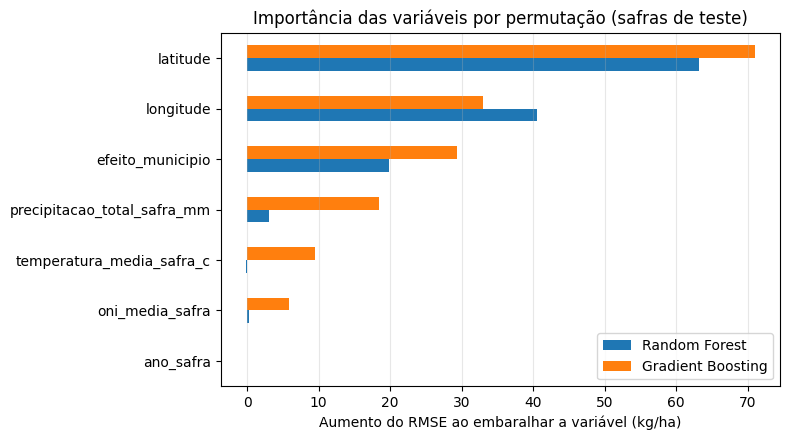

,Random Forest,Gradient Boosting
latitude,63.00,71.00
longitude,41.00,33.00
efeito_municipio,20.00,29.00
precipitacao_total_safra_mm,3.00,18.00
temperatura_media_safra_c,-0.00,9.00
oni_media_safra,0.00,6.00
ano_safra,0.00,0.00


In [13]:
importancias = {}
for nome, modelo in [("Random Forest", rf), ("Gradient Boosting", gb)]:
    r = permutation_importance(modelo, teste[FEAT_ARVORE], y_teste, n_repeats=10,
                               random_state=SEED, scoring="neg_root_mean_squared_error",
                               n_jobs=-1)
    importancias[nome] = pd.Series(r.importances_mean, index=FEAT_ARVORE)

importancias = pd.DataFrame(importancias).sort_values("Gradient Boosting")
ax = importancias.plot.barh(figsize=(8, 4.5))
ax.set_xlabel("Aumento do RMSE ao embaralhar a variável (kg/ha)")
ax.set_title("Importância das variáveis por permutação (safras de teste)")
ax.grid(axis="x", alpha=0.3)
plt.tight_layout()
plt.show()
importancias.sort_values("Gradient Boosting", ascending=False).round(0)

## 12. Observado × previsto (melhor modelo)

Cada ponto é um município em uma safra de teste. Pontos sobre a diagonal são
previsões perfeitas.

Melhor modelo pelo RMSE: 1a - OLS (só clima)


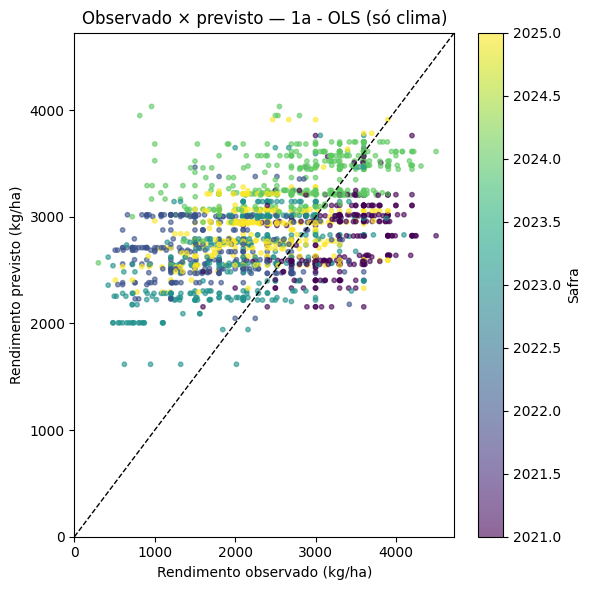

In [14]:
melhor = comparacao["RMSE (kg/ha)"].idxmin()
print("Melhor modelo pelo RMSE:", melhor)

fig, ax = plt.subplots(figsize=(6, 6))
anos = teste["ano_safra"]
sc = ax.scatter(y_teste, previsoes[melhor], c=anos, cmap="viridis", s=10, alpha=0.6)
lim = [0, max(y_teste.max(), np.max(previsoes[melhor])) * 1.05]
ax.plot(lim, lim, "k--", lw=1)
ax.set_xlim(lim)
ax.set_ylim(lim)
ax.set_xlabel("Rendimento observado (kg/ha)")
ax.set_ylabel("Rendimento previsto (kg/ha)")
ax.set_title(f"Observado × previsto — {melhor}")
fig.colorbar(sc, ax=ax, label="Safra")
plt.tight_layout()
plt.show()

## 13. O erro depende da distância até a estação INMET?

Esta é a evidência para decidir a Etapa 3. Se o erro cresce quando a estação está
mais longe do município, o clima da estação está representando mal o clima local — e
uma fonte em grade (NASA POWER), que dá o clima na coordenada de cada município, tende
a ajudar. Também mostramos quantas linhas de 2021–2025 ficaram **fora** do teste por
falta de clima do INMET.

In [15]:
erro_abs = (y_teste - previsoes[melhor]).abs()
faixas = pd.cut(teste["dist_km"], bins=[0, 15, 30, 45, 80],
                labels=["0-15 km", "15-30 km", "30-45 km", "45-80 km"])
print(f"MAE do melhor modelo ({melhor}) por distância município–estação:")
display(erro_abs.groupby(faixas, observed=True).agg(["mean", "count"])
        .rename(columns={"mean": "MAE (kg/ha)", "count": "linhas"}).round(0))

rho, p = stats.spearmanr(teste["dist_km"], erro_abs)
print(f"Correlação de Spearman distância × erro absoluto: {rho:+.3f} (p = {p:.3f})")

periodo_teste = com_rendimento[com_rendimento["ano_safra"] > ANO_CORTE]
sem_clima = periodo_teste[CHUVA].isna() | periodo_teste[TEMP].isna()
print(f"\nSafras 2021-2025 com rendimento: {len(periodo_teste)} linhas — "
      f"{sem_clima.sum()} ({sem_clima.mean():.0%}) sem clima do INMET, fora do teste")

MAE do melhor modelo (1a - OLS (só clima)) por distância município–estação:


,MAE (kg/ha),linhas
dist_km,,
0-15 km,742.00,262
15-30 km,746.00,592
30-45 km,693.00,569
45-80 km,760.00,321


Correlação de Spearman distância × erro absoluto: -0.014 (p = 0.547)

Safras 2021-2025 com rendimento: 2154 linhas — 410 (19%) sem clima do INMET, fora do teste


## 14. Diagnóstico: o total de chuva da safra esconde *quando* a chuva caiu

A tabela abaixo compara, por safra, o rendimento médio com a **chuva total out–mar**
(a variável usada no modelo) e com a chuva dividida em subperíodos do ciclo, calculada
a partir dos dados diários brutos do INMET (média entre as estações):

- **out–nov:** semeadura e emergência
- **dez–fev:** floração e enchimento de grãos (período crítico da soja)
- **mar:** fim do enchimento / maturação
- **abr–mai:** colheita (fora da janela usada no painel)

In [16]:
inmet = pd.read_csv(f"{RAW}/inmet_estacoes_RS_consolidado_2000_2025.csv", sep=";", decimal=",",
                    usecols=["Codigo Estacao", "Data Medicao", "PRECIPITACAO TOTAL, DIARIO (AUT)(mm)"])
inmet.columns = ["estacao", "data", "chuva_mm"]
inmet["data"] = pd.to_datetime(inmet["data"])
inmet["chuva_mm"] = pd.to_numeric(inmet["chuva_mm"], errors="coerce")
mes = inmet["data"].dt.month
inmet["ano_safra"] = inmet["data"].dt.year + (mes >= 10)   # out-dez contam para a safra seguinte
inmet["subperiodo"] = pd.cut(mes.where(mes >= 4, mes + 12), bins=[3, 5, 9, 11, 14, 15],
                             labels=["abr-mai", "fora", "out-nov", "dez-fev", "mar"])

chuva_sub = (inmet[inmet["subperiodo"] != "fora"]
             .groupby(["ano_safra", "estacao", "subperiodo"], observed=True)["chuva_mm"].sum()
             .groupby(["ano_safra", "subperiodo"], observed=True).mean()
             .unstack()[["out-nov", "dez-fev", "mar", "abr-mai"]])

resumo = (df.groupby("ano_safra")
          .agg(rendimento_medio=(ALVO, "mean"), chuva_total_out_mar=(CHUVA, "mean"))
          .join(chuva_sub))
resumo.loc[2017:2025].round(0)

,rendimento_medio,chuva_total_out_mar,out-nov,dez-fev,mar,abr-mai
ano_safra,,,,,,
2017,"3,343.00","1,055.00",352.00,404.00,145.00,462.00
2018,"3,157.00",876.00,338.00,330.00,139.00,192.00
2019,"3,220.00",990.00,311.00,461.00,117.00,339.00
2020,"1,974.00",752.00,388.00,270.00,32.00,185.00
2021,"3,293.00",702.00,116.00,359.00,117.00,156.00
2022,"1,716.00",659.00,145.00,200.00,148.00,281.00
2023,"2,075.00",567.00,169.00,225.00,113.00,188.00
2024,"2,865.00","1,341.00",532.00,408.00,150.00,622.00
2025,"2,330.00",662.00,228.00,300.00,60.00,251.00


## 15. Conclusões da Etapa 1 e próximos passos

**Resultado principal:** nenhum dos modelos base generalizou para as safras 2021–2025.
Todos tiveram **R² negativo no teste**, ou seja, erraram mais do que um palpite
constante igual à média do período. O melhor foi a **OLS só com clima** (RMSE ≈ 900
kg/ha, MAE ≈ 730 kg/ha), seguida da OLS com município, do Gradient Boosting, do Random
Forest e, por último, da baseline. No treino, os mesmos modelos explicam de 31% (OLS) a
90% (árvores) da variação: o problema não é falta de ajuste, é que **as variáveis atuais
não carregam a informação que distingue as safras recentes**.

**Por que os modelos erraram (seções 10 e 14):**

1. **O total de chuva out–mar esconde quando a chuva caiu.** As safras 2021 e 2022
   tiveram total de chuva parecido (~700 e ~660 mm), mas 2021 foi recorde (~3.290
   kg/ha) e 2022 foi quebra (~1.720 kg/ha). A diferença está no período crítico:
   dez–fev teve ~360 mm em 2021 e só ~200 mm em 2022. Com uma única variável de chuva
   total, o modelo não tem como separar os dois casos.
2. **Parte do evento fica fora da janela.** Em 2024 a chuva total foi a maior da série
   (~1.340 mm), então os modelos previram safra excelente, mas o rendimento ficou em
   ~2.870 kg/ha. O excesso de chuva caiu na semeadura (out–nov, ~530 mm) e na colheita
   (abr–mai, ~620 mm, enchentes de 2024), e a janela out–mar não vê a colheita.
3. **A tendência tecnológica foi extrapolada para cima.** A reta de +74 kg/ha por ano
   previa mais de 3.000 kg/ha para 2021–2025, mas o período teve três secas em cinco
   safras. Isso explica por que a baseline foi o pior modelo.
4. **As árvores não extrapolam o tempo.** No Random Forest e no Gradient Boosting, a
   importância de `ano_safra` é zero: para eles, qualquer safra depois de 2020 "é
   2020". Eles também se apoiaram muito em latitude/longitude, que descrevem *onde*
   rende mais, mas não *em que ano*.

**Sobre a Etapa 3 (NASA POWER):** o erro **não cresce** com a distância até a estação
INMET (correlação de Spearman ≈ 0, MAE parecido em todas as faixas de distância).
Portanto, a qualidade espacial do clima das estações não é o gargalo agora. Uma fonte
em grade só aumentaria a cobertura (19% das linhas de 2021–2025 estão fora do teste
por falta de clima), sem corrigir os erros acima.

**Próximo passo recomendado: reagregar o clima que já temos, sem buscar dados novos.**
Os dados diários do INMET já permitem:

- dividir a chuva em subperíodos (out–nov, dez–fev, mar) e incluir abr–mai (colheita);
- criar indicadores de estresse no período crítico: dias secos consecutivos, dias com
  temperatura máxima acima de ~32 °C e média da temperatura máxima em dez–fev;
- treinar as árvores no **desvio em relação à tendência** (rendimento − tendência)
  em vez do rendimento bruto, para que elas não precisem extrapolar o ano;
- validar com **"deixa uma safra de fora"** (*leave-one-year-out*) além do corte
  2020/2021, para que o resultado não dependa de um único período atípico.